# F3 — Feature Engineering

Genera el dataset listo para modelar (`processed/features.parquet` + `.csv`)
a partir de `interim/matches.parquet` y `interim/rankings.parquet`, con features
diferenciales `team1 − team2` **sin fuga de datos**.

Módulo: `src/features.py`.

In [1]:
# Monta Google Drive (solo en Colab) para acceder a los datos y a src/.
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # fuera de Colab (local)


Mounted at /content/drive


In [2]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np

# Asegurar que src/ esté en el path (local o Colab)
ROOT = Path("/content/drive/MyDrive/Analisis de datos/Proyecto final")
if not ROOT.exists():
    ROOT = Path.cwd()  # fallback local
if (ROOT / "src").exists():
    sys.path.insert(0, str(ROOT / "src"))

from features import (build_features, parse_date, build_target,
                      add_differential_features, norm_name)

# Ruta a los datos (ajústala en Colab/Drive)
DATA_DIR = str(ROOT / "data")

## 1. Demo de las piezas (target + parseo de fecha)

In [3]:
raw = pd.read_parquet(f"{DATA_DIR}/interim/matches.parquet")
print("raw matches:", raw.shape)

targeted = build_target(raw)
print("tras build_target (y + filtrado de draw/forfeit):", targeted.shape)
print("balance y:\n", targeted["y"].value_counts(normalize=True).round(4))

print("parse_date('Thu, October 22, 2026') ->", parse_date("Thu, October 22, 2026"))
print("parse_date('2d 0h ago') ->", parse_date("2d 0h ago"))
print("norm_name('LEVIATÁN') ->", norm_name("LEVIATÁN"))

raw matches: (108448, 13)
tras build_target (y + filtrado de draw/forfeit): (107268, 14)
balance y:
 y
1    0.5908
0    0.4092
Name: proportion, dtype: float64
parse_date('Thu, October 22, 2026') -> 2026-10-22 00:00:00
parse_date('2d 0h ago') -> None
norm_name('LEVIATÁN') -> leviatan


## 2. Pipeline completo

In [4]:
df = build_features(DATA_DIR)
print("shape:", df.shape)
df.head()

shape: (107242, 22)


,match_id,team1,team2,date,date_ts,event,stage,score1,score2,y,...,f_rank_diff,f_form_diff,f_winrate_diff,f_mapscore_diff,f_experience_diff,f_rest_diff,f_streak_diff,f_map_winrate_diff,f_profile_rating_diff,f_winnings_diff
0,190,TooGoodForLan,L'institut,"Sat, April 25, 2020",1587819600,COOLER Cup,Playoffs,7.0,13.0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,191,Prodigy,fish123,"Sat, April 25, 2020",1587819600,COOLER Cup,Playoffs,5.0,13.0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,192,Ninjas in Pyjamas,need more DM,"Sat, April 25, 2020",1587823200,COOLER Cup,Playoffs,2.0,0.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,193,L'institut,fish123,"Sat, April 25, 2020",1587823200,COOLER Cup,Playoffs,0.0,0.0,0,...,0.0,0.0,0.0,-2.0,0.0,0.0,0.0,0.0,0.0,0.0
4,194,Ninjas in Pyjamas,fish123,"Sat, April 25, 2020",1587830400,COOLER Cup,Playoffs,0.0,2.0,0,...,0.0,0.0,0.0,-2.0,-1.0,0.0,-1.0,0.0,0.0,0.0


## 3. Chequeo de nulos y balance del target

In [5]:
print("Nulos por columna:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nBalance del target (y = 1 gana team1):")
print(df["y"].value_counts(normalize=True).round(4))

Nulos por columna:
Series([], dtype: int64)

Balance del target (y = 1 gana team1):
y
1    0.5908
0    0.4092
Name: proportion, dtype: float64


## 4. Tipos de datos

In [6]:
df.dtypes

,0
match_id,object
team1,object
team2,object
date,object
date_ts,int64
event,object
stage,object
score1,float64
score2,float64
y,int8


## 5. Correlación de las features `f_*`

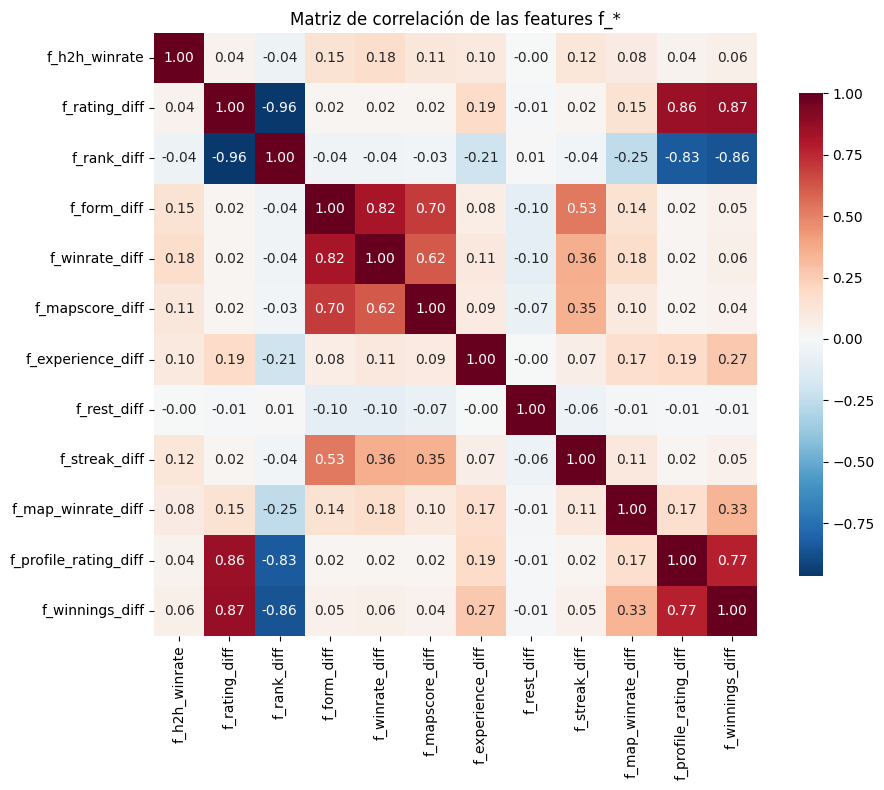

,f_h2h_winrate,f_rating_diff,f_rank_diff,f_form_diff,f_winrate_diff,f_mapscore_diff,f_experience_diff,f_rest_diff,f_streak_diff,f_map_winrate_diff,f_profile_rating_diff,f_winnings_diff
f_h2h_winrate,1.00,0.04,-0.04,0.15,0.18,0.11,0.10,-0.00,0.12,0.08,0.04,0.06
f_rating_diff,0.04,1.00,-0.96,0.02,0.02,0.02,0.19,-0.01,0.02,0.15,0.86,0.87
f_rank_diff,-0.04,-0.96,1.00,-0.04,-0.04,-0.03,-0.21,0.01,-0.04,-0.25,-0.83,-0.86
f_form_diff,0.15,0.02,-0.04,1.00,0.82,0.70,0.08,-0.10,0.53,0.14,0.02,0.05
f_winrate_diff,0.18,0.02,-0.04,0.82,1.00,0.62,0.11,-0.10,0.36,0.18,0.02,0.06
f_mapscore_diff,0.11,0.02,-0.03,0.70,0.62,1.00,0.09,-0.07,0.35,0.10,0.02,0.04
f_experience_diff,0.10,0.19,-0.21,0.08,0.11,0.09,1.00,-0.00,0.07,0.17,0.19,0.27
f_rest_diff,-0.00,-0.01,0.01,-0.10,-0.10,-0.07,-0.00,1.00,-0.06,-0.01,-0.01,-0.01
f_streak_diff,0.12,0.02,-0.04,0.53,0.36,0.35,0.07,-0.06,1.00,0.11,0.02,0.05
f_map_winrate_diff,0.08,0.15,-0.25,0.14,0.18,0.10,0.17,-0.01,0.11,1.00,0.17,0.33


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

feats = [c for c in df.columns if c.startswith("f_")]
corr = df[feats].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, cbar_kws={"shrink": 0.8})
plt.title("Matriz de correlación de las features f_*")
plt.tight_layout()
plt.show()

corr.round(2)

## Interpretación

- **`f_rating_diff` / `f_rank_diff`** son una *foto actual* del ranking (no histórico).
- **`f_form_diff`, `f_winrate_diff`, `f_h2h_winrate`, `f_mapscore_diff`,
  `f_experience_diff`, `f_rest_diff`, `f_streak_diff`** usan SOLO partidos previos
  (rolling/tiempos), por lo que son libres de fuga.
- El **split temporal** se hace en la fase de modelado usando `date`/`date_ts`.